In [1]:
import numpy as np
import pandas as pd
import xarray as xr 
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)

In [2]:
plotdir = "/home/kperny/VolMIP_stratosphere/plots/PAPER/"
piControl = pd.read_csv("/home/kperny/VolMIP_stratosphere/tab/ta_ua_piControl.csv")
df_flags = pd.read_csv("/home/kperny/VolMIP_stratosphere/tab/nao_change.csv")
models = df_flags.model.unique()

In [3]:
df = df_flags.set_index(['model', 'realization'])
df['count'] = 1
# get amount of realizations of each NAO state in piControl
df_out = df.where((df['experiment']=='piControl')).dropna().drop(columns=['experiment', 'nao']).groupby(['model', 'nao_flag']).sum()
df_out = df_out.reset_index().set_index('nao_flag')
df_rel = df_out.copy()

# create index based on NAO state for piControl
naon = df.where((df['experiment']=='piControl') & (df['nao_flag'] == -1)).dropna().index
naop = df.where((df['experiment']=='piControl') & (df['nao_flag'] == 1)).dropna().index
nao0 = df.where((df['experiment']=='piControl') & (df['nao_flag'] == 0)).dropna().index

# iterate over NAO state and count state changes in volc
states = ['NAO-', 'NAO0', 'NAO+']
for idx, value in zip([naon, naop, nao0], [-1, 1, 0]):
    volc = df.where(df['experiment']=='volc').loc[idx].dropna().drop(columns=['experiment', 'nao'])
    df_out.loc[value, states] = volc.groupby(['model', 'nao_flag']).sum().unstack().values
    # normalize by the amount of realizations in piControl
    df_rel.loc[value, states] = volc.groupby(['model', 'nao_flag']).sum().unstack().values / df_out.reset_index().set_index(['nao_flag', 'model']).loc[value]['count'].values.reshape(5,1)
df_nao = df_out.reset_index().set_index(['nao_flag', 'model']).sort_index()
df_nao = df_nao.fillna(0)

df_rel = df_rel.reset_index().set_index(['nao_flag', 'model']).sort_index()
df_rel = df_rel.fillna(0)

# calculate percantage and round to integer
df_pro = df_rel.copy()
df_pro[states] = df_pro[states] *100

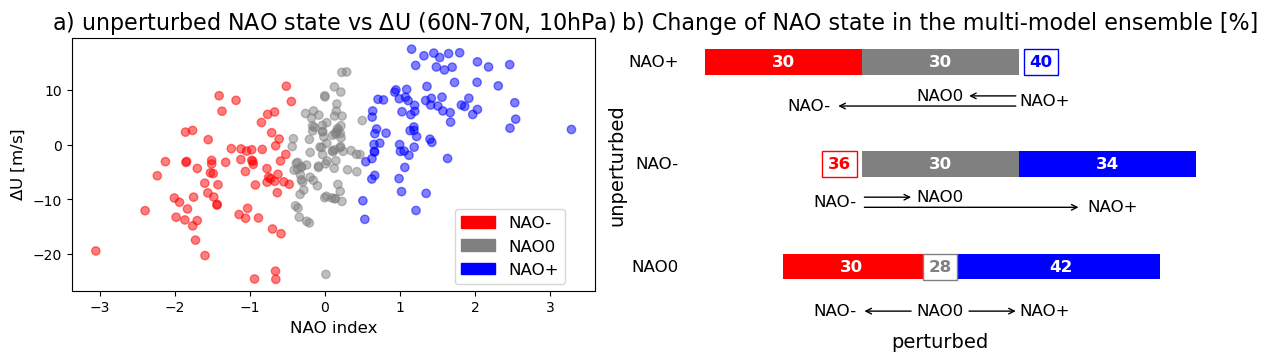

In [5]:
fig, axes = plt.subplots(1,2, figsize=(12,3.5), layout='constrained')

###### FIGURE A
# data = piControl.groupby(['model','nao_flag']).mean('model').reset_index()
axes[0].set_title('a) unperturbed NAO state vs $\Delta$U (60N-70N, 10hPa)', fontsize=16)
axes[0].scatter(piControl['nao'], piControl['deltaU'], c=piControl['nao_flag'].map({-1: 'red', 0: 'grey', 1: 'blue'}), alpha=0.5)
axes[0].set_ylabel('$\Delta$U [m/s]',fontsize=12,)
axes[0].set_xlabel('NAO index', fontsize=12)

###### FIGURE B

axs = axes[1]
data = df_pro.groupby(['nao_flag']).mean().round(0).apply(pd.to_numeric, downcast='integer')

axs.barh('NAO0', -data.loc[0]['NAO-'], height=0.25, color = 'r')
axs.barh('NAO0', data.loc[0]['NAO+'], height=0.25, color = 'b')

axs.barh('NAO-', data.loc[-1]['NAO+'] + data.loc[-1]['NAO0'] / 2, height=0.25, color = 'b')
axs.barh('NAO-', -data.loc[-1]['NAO0']/ 2, height=0.25, color = 'grey')
axs.barh('NAO-', data.loc[-1]['NAO0'] / 2, height=0.25, color = 'grey')

axs.barh('NAO+', -data.loc[1]['NAO-'] - data.loc[1]['NAO0'] / 2, height=0.25, color = 'r')
axs.barh('NAO+', -data.loc[1]['NAO0']/ 2, height=0.25, color = 'grey')
axs.barh('NAO+', data.loc[1]['NAO0'] / 2, height=0.25, color = 'grey')


axs.set_xlim(-50, 50)
# Annnotate piControl NAO+
axs.annotate(data.loc[1]['NAO-'], xy=( - data.loc[1]['NAO0'] / 2 - data.loc[1]['NAO-'] / 2, 'NAO+'), xycoords='data', ha='center', va='center',
             fontsize=12, weight='bold', color='white')
axs.annotate(data.loc[1]['NAO0'], xy=(0, 'NAO+'), xycoords='data', ha='center', va='center',
             fontsize=12, weight='bold', color='white')
axs.annotate(data.loc[1]['NAO+'], xy=(data.loc[1]['NAO0'] / 2 + 2, 'NAO+'), xycoords='data', ha='left', va='center',
             fontsize=12, weight='bold', color='b', bbox=dict(fc='white', ec='b'))

# Annotate piControl NAO-
axs.annotate(data.loc[-1]['NAO-'], xy=(- data.loc[-1]['NAO0'] / 2 - 2, 'NAO-'), xycoords='data', ha='right', va='center',
             fontsize=12, weight='bold', color='r', bbox=dict(fc='white', ec='r'))
axs.annotate(data.loc[-1]['NAO0'], xy=(0, 'NAO-'), xycoords='data', ha='center', va='center',
             fontsize=12, weight='bold', color='white')
axs.annotate(data.loc[-1]['NAO+'], xy=(data.loc[-1]['NAO0'] / 2 + data.loc[-1]['NAO+'] / 2, 'NAO-'), xycoords='data', ha='center', va='center',
             fontsize=12, weight='bold', color='white')

# Annnotate piControl NAO0
axs.annotate(data.loc[0]['NAO-'], xy=(- data.loc[0]['NAO-'] / 2 - 2, 'NAO0'), xycoords='data', ha='center', va='center',
             fontsize=12, weight='bold', color='white')
axs.annotate(data.loc[0]['NAO0'], xy=(0, 'NAO0'), xycoords='data', ha='center', va='center',
             fontsize=12, weight='bold', color='grey', bbox=dict(fc='white', ec='grey'))
axs.annotate(data.loc[0]['NAO+'], xy=(data.loc[0]['NAO+'] / 2 + 2, 'NAO0'), xycoords='data', ha='center', va='center',
             fontsize=12, weight='bold', color='white')

# axis labels
axs.set_axis_off()
axs.annotate('', xy=(0.35, -0.08), xycoords='axes fraction', xytext=(0.45, -0.08), 
        arrowprops=dict(arrowstyle="->", color='k'))
axs.annotate('', xy=(0.55, -0.08), xycoords='axes fraction', xytext=(0.65, -0.08), 
        arrowprops=dict(arrowstyle="<-", color='k'))
axs.annotate('', xy=(0.45, 0.37), xycoords='axes fraction', xytext=(0.35, 0.37), 
        arrowprops=dict(arrowstyle="->", color='k'))
axs.annotate('', xy=(0.77, 0.33), xycoords='axes fraction', xytext=(0.35, 0.33), 
        arrowprops=dict(arrowstyle="->", color='k'))
axs.annotate('', xy=(0.65, 0.77), xycoords='axes fraction', xytext=(0.55, 0.77), 
        arrowprops=dict(arrowstyle="<-", color='k'))
axs.annotate('', xy=(0.65, 0.73), xycoords='axes fraction', xytext=(0.3, 0.73), 
        arrowprops=dict(arrowstyle="<-", color='k'))

axs.annotate('NAO0', xy=(0.5, 0.77), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')
axs.annotate('NAO0', xy=(0.5, 0.37), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')
axs.annotate('NAO-', xy=(0.25, 0.73), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')
axs.annotate('NAO-', xy=(0.3, 0.35), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')
axs.annotate('NAO+', xy=(0.7, 0.75), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')
axs.annotate('NAO+', xy=(0.83, 0.33), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')

# axs.annotate('', xy=(0.35, -0.08), xycoords='axes fraction', xytext=(0.45, -0.08), 
#         arrowprops=dict(arrowstyle="-", color='k'))
# axs.annotate('', xy=(0.55, -0.08), xycoords='axes fraction', xytext=(0.65, -0.08), 
#         arrowprops=dict(arrowstyle="-", color='k'))
axs.annotate('NAO-', xy=(0.3, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')
axs.annotate('NAO0', xy=(0.5, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')
axs.annotate('NAO+', xy=(0.7, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')
axs.annotate('perturbed', xy=(0.5, -0.2), xycoords='axes fraction', ha='center', va='center', fontsize=14, color='k')

# ylabels
axs.annotate('NAO+', xy=(-50, 'NAO+'), xycoords='data', ha='right', va='center', fontsize=12, color='k', annotation_clip=False)
axs.annotate('NAO-', xy=(-50, 'NAO-'), xycoords='data', ha='right', va='center', fontsize=12, color='k', annotation_clip=False)
axs.annotate('NAO0', xy=(-50, 'NAO0'), xycoords='data', ha='right', va='center', fontsize=12, color='k', annotation_clip=False)
axs.annotate('unperturbed', xy=(-60, 'NAO-'), xycoords='data', ha='right', va='center', fontsize=14, color='k', rotation=90, annotation_clip=False)

# legend
import matplotlib.patches as mpatches
blue_patch = mpatches.Patch(color='blue', label='NAO+')
green_patch = mpatches.Patch(color='grey', label='NAO0')
red_patch = mpatches.Patch(color='red', label='NAO-')

fig.legend(handles=[red_patch, green_patch, blue_patch], loc='center', ncol=1, fontsize=12, bbox_to_anchor=(0.42,0.31))

axs.set_title('b) Change of NAO state in the multi-model ensemble [%]', fontsize=16)

plt.savefig(plotdir + 'figure1.png', dpi=200, bbox_inches='tight')

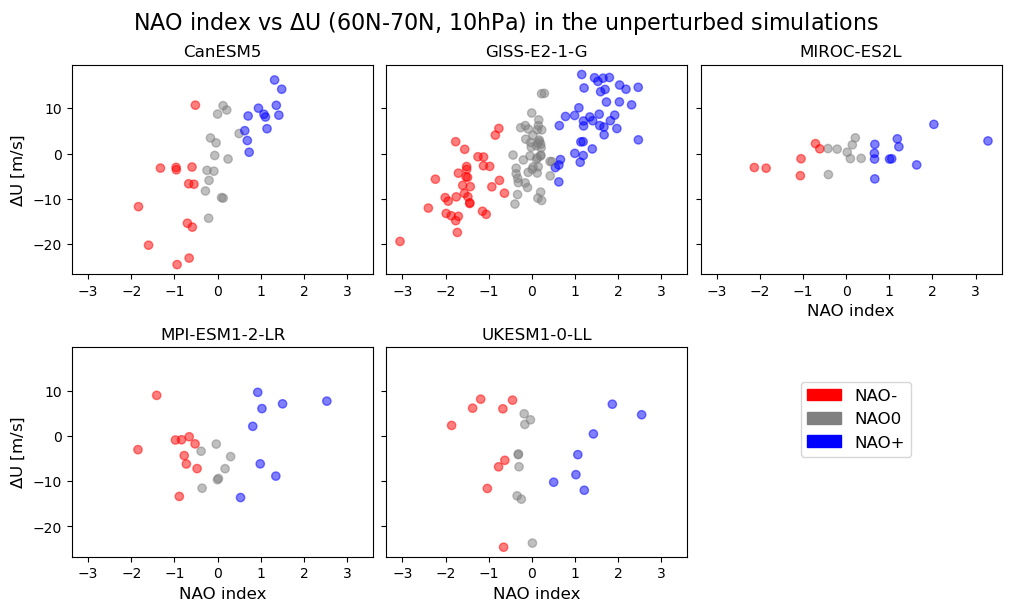

In [6]:
fig, axs = plt.subplots(2,3, figsize=(10,6), sharey=True, sharex=True, layout='constrained')

data = piControl.set_index(['model','realization'])
for ax, model in zip(axs.flat, models):
    tmp = data.loc[model]
    ax.scatter(tmp['nao'], tmp['deltaU'], c=tmp['nao_flag'].map({-1: 'red', 0: 'grey', 1: 'blue'}), alpha=0.5)
    ax.set_title(model, fontsize=12)
axs[-1,-1].set_axis_off()
fig.suptitle('NAO index vs $\Delta$U (60N-70N, 10hPa) in the unperturbed simulations', fontsize=16)
axs[0,0].set_ylabel('$\Delta$U [m/s]', fontsize=12)
axs[1,0].set_ylabel('$\Delta$U [m/s]', fontsize=12)
axs[1,0].set_xlabel('NAO index', fontsize=12)
axs[1,1].set_xlabel('NAO index', fontsize=12)
axs[0,2].set_xlabel('NAO index', fontsize=12)
axs[0,2].xaxis.set_tick_params(labelbottom=True)
axs[0,1].xaxis.set_tick_params(labelbottom=True)
axs[0,0].xaxis.set_tick_params(labelbottom=True)

# legend
import matplotlib.patches as mpatches
blue_patch = mpatches.Patch(color='blue', label='NAO+')
green_patch = mpatches.Patch(color='grey', label='NAO0')
red_patch = mpatches.Patch(color='red', label='NAO-')

fig.legend(handles=[red_patch, green_patch, blue_patch], loc='center', ncol=1, fontsize=12, bbox_to_anchor=(0.85,0.31))


plt.savefig(plotdir + 'supp1.png', dpi=200, bbox_inches='tight')

In [7]:
# ### ADD LINEAR REGRESSION???

# model = LinearRegression()
# # Train the model
# model.fit(piControl[['nao']], piControl['deltaU'])

# # Evaluate the model
# r2_score = model.score(piControl[['nao']], piControl['deltaU'])
# print(f"R-squared value: {r2_score}")

# test = piControl.set_index(['model','realization']).loc[models[[0]]]
# model = LinearRegression()
# # Train the model

# # Evaluate the model
# r2_score = model.score(test[['nao']], test['deltaU'])
# print(f"R-squared value: {r2_score}")

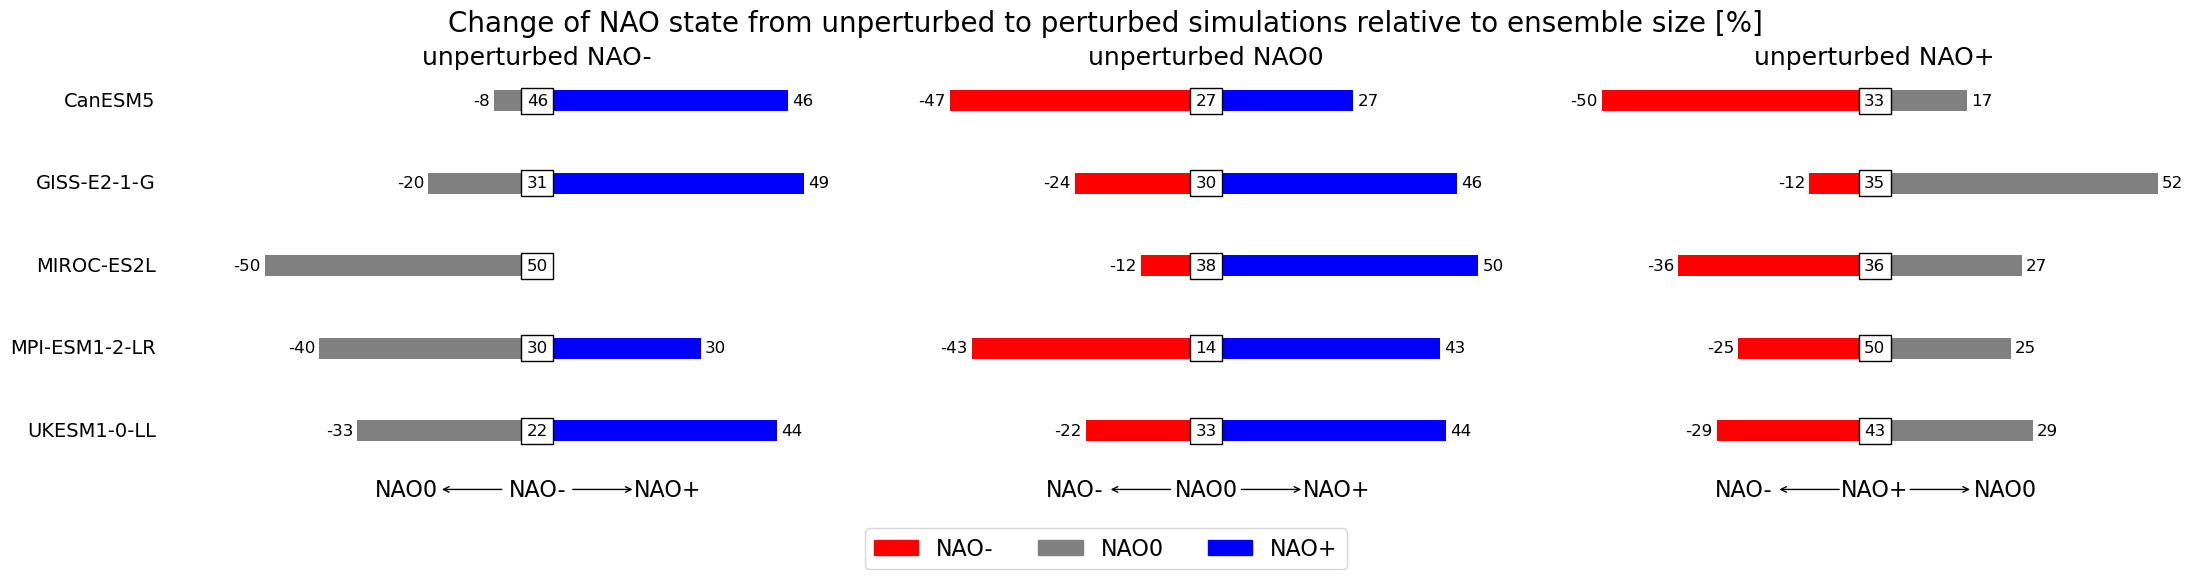

In [9]:
df_pro = df_pro.round(0).apply(pd.to_numeric, downcast='integer')

fig, axs = plt.subplots(1,3, figsize=(22, 5), sharey=True, layout='constrained')

data = df_pro.loc[-1].reset_index()
axs[0].barh(data['model'], data['NAO+'], height=0.25, color = 'b')
axs[0].barh(data['model'], -data['NAO0'], height=0.25, color = 'grey')

data = df_pro.loc[0].reset_index()
axs[1].barh(data['model'], -data['NAO-'], height=0.25, color = 'r')
axs[1].barh(data['model'], data['NAO+'], height=0.25, color = 'b')

data = df_pro.loc[1].reset_index()
axs[2].barh(data['model'], -data['NAO-'], height=0.25, color = 'r')
axs[2].barh(data['model'], data['NAO0'], height=0.25, color = 'grey')


for ax, nao, state, color in zip(axs, [-1,0,1], ['NAO-', 'NAO0', 'NAO+'], ['red', 'grey', 'blue']):
    ax.set_xlim(-60, 60)
    for container in ax.containers:
        ax.bar_label(container, label_type='edge', padding=3, fontsize=12)
    for model in models:
        ax.annotate(df_pro.loc[nao, model][state], xy=(0, model), xycoords='data', ha='center', va='center',
                    fontsize=12, color='black', bbox=dict(fc='white'))
    # ax.set_xlabel(state, fontsize=16)
    ax.set_axis_off()
    ax.invert_yaxis()

    # ax.set_ylabel(data[model].values)
    ax.annotate('', xy=(0.35, -0.08), xycoords='axes fraction', xytext=(0.45, -0.08), 
            arrowprops=dict(arrowstyle="->", color='k'))
    ax.annotate('', xy=(0.55, -0.08), xycoords='axes fraction', xytext=(0.65, -0.08), 
            arrowprops=dict(arrowstyle="<-", color='k'))

# axs[0].tick_params(axis='both', labelsize=12)
    
axs[0].annotate('NAO0', xy=(0.3, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[0].annotate('NAO-', xy=(0.5, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[0].annotate('NAO+', xy=(0.7, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')

axs[1].annotate('NAO-', xy=(0.3, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[1].annotate('NAO0', xy=(0.5, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[1].annotate('NAO+', xy=(0.7, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')

axs[2].annotate('NAO-', xy=(0.3, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[2].annotate('NAO+', xy=(0.5, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[2].annotate('NAO0', xy=(0.7, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')

for i, model in enumerate(models):
    axs[0].annotate(model, xy=(-70,i), xycoords='data', ha='right', va='center', fontsize=14, color='k', annotation_clip=False)

axs[0].set_title('unperturbed NAO-', fontsize=18)
axs[1].set_title('unperturbed NAO0', fontsize=18)
axs[2].set_title('unperturbed NAO+', fontsize=18)

import matplotlib.patches as mpatches
blue_patch = mpatches.Patch(color='red', label='NAO-')
green_patch = mpatches.Patch(color='grey', label='NAO0')
red_patch = mpatches.Patch(color='blue', label='NAO+')
fig.legend(handles=[blue_patch, green_patch, red_patch], loc='lower center', ncol=3, fontsize=16, bbox_to_anchor=(0.5, -0.15))

plt.suptitle('Change of NAO state from unperturbed to perturbed simulations relative to ensemble size [%]', fontsize=20)
plt.savefig(plotdir + 'supp2.png', dpi=200, bbox_inches='tight')